In [1]:
import sys
sys.path.append("../")

import numpy as np
import matplotlib.pyplot as plt
import cv2
import pickle

import pylops
from matplotlib import colors
import matplotlib as mpl

import scipy.io as sio

from nopt.transforms import *
from nopt.constraints import *
from nopt.problems import *
from nopt.solvers import *
import h5py
from sklearn.metrics.cluster import adjusted_rand_score


In [2]:
experiment_name = 'ds1'
with open(experiment_name+ '.pickle', 'rb') as handle:
    results = pickle.load(handle)

In [111]:
labels_full = results['full']['labels']
for key_delta, d_exper in results.items():
    if key_delta != 'full':
        print('Delta: '+str(key_delta))
        rhos_s = 'Rhos: '
        sparsities = 'Sparsities: '
        errors_lrps = 'Errors LRPS: '
        aris = '1-ARI: '
        for key_rho_s, s_exper in d_exper.items():
            labels_subsampled = s_exper['labels']
            rhos_s = rhos_s + str(key_rho_s) + ', '
            sparsity = "%d" % np.round(key_rho_s * np.prod(results['full']['tensor_shape']))
            sparsities = sparsities + sparsity + ', '
            errors_lrps = errors_lrps + '&'+ ("%.3f" % s_exper['error_lrps']) + ' '
            ari = adjusted_rand_score(labels_full, labels_subsampled)
            aris = aris + '&'+("%.3f" % (1-ari)) + ' '
        print(rhos_s)
        print(sparsities)
        print(errors_lrps)
        print(aris)

Delta: d001
Rhos: 0.1, 0.01, 0.001, 0.0001, 1e-05, 
Sparsities: 151995, 15199, 1520, 152, 15, 
Errors LRPS: &1.072 &1.027 &2.108 &16.219 &1.026 
1-ARI: &1.003 &1.005 &1.004 &1.000 &0.995 
Delta: d005
Rhos: 0.1, 0.01, 0.001, 0.0001, 1e-05, 
Sparsities: 151995, 15199, 1520, 152, 15, 
Errors LRPS: &0.871 &0.873 &0.847 &0.874 &0.844 
1-ARI: &0.985 &0.981 &0.989 &0.990 &0.990 
Delta: d020
Rhos: 0.1, 0.01, 0.001, 0.0001, 1e-05, 
Sparsities: 151995, 15199, 1520, 152, 15, 
Errors LRPS: &0.606 &0.298 &0.188 &0.118 &0.197 
1-ARI: &0.985 &0.698 &0.444 &0.357 &0.650 


In [112]:
labels_full = results['full']['labels']
rho_s = 1e-4
labels_subsampled = results['d020'][rho_s]['labels']

In [113]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

/var/folders/ft/w6n5p71s4fbbpd1dypjt09sm0000gs/T/ipykernel_4581/1320315831.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('Set1', rank)    # 11 discrete colors


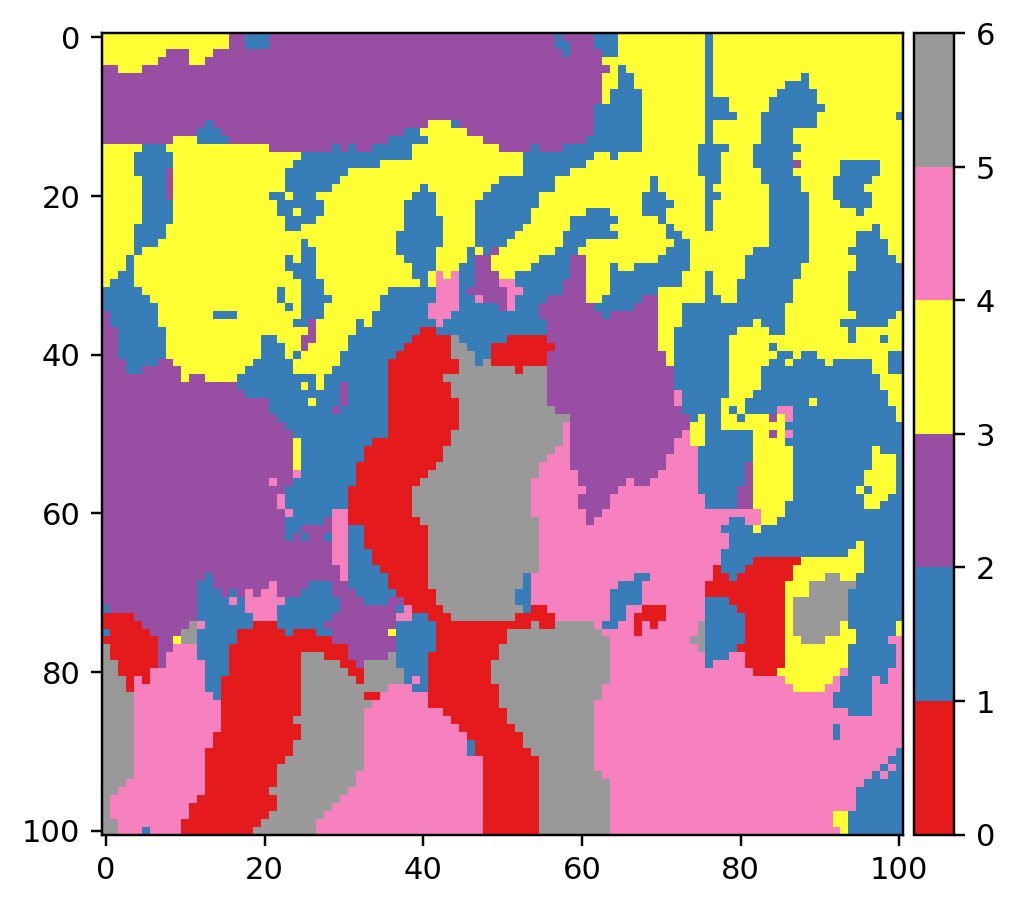

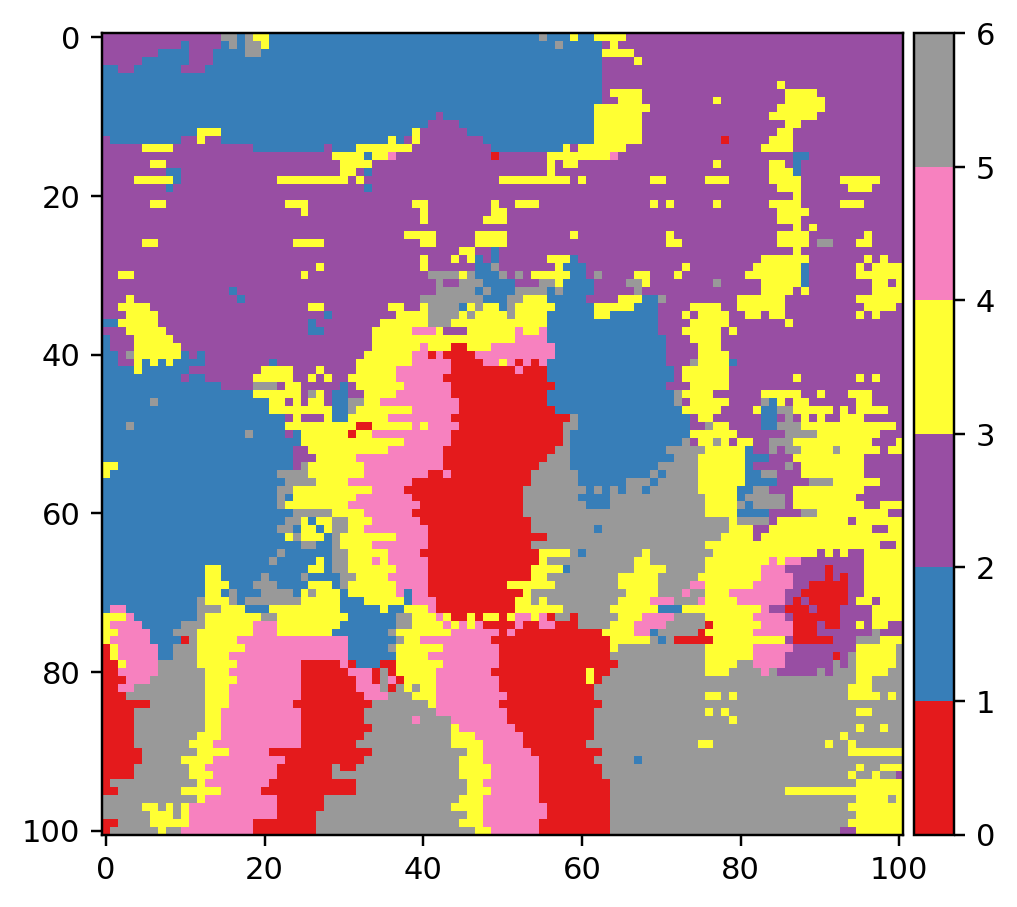

In [114]:

figsize = (5, 5)

rank = results['full']['rank']

cmap = plt.cm.get_cmap('Set1', rank)    # 11 discrete colors
cmaplist = [cmap(i) for i in range(cmap.N)]
bounds = np.linspace(0, rank, rank+1)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)

shape = results['full']['tensor_shape'][1:]
plt.figure(figsize=figsize, dpi= 220)
ax = plt.gca()
im = ax.imshow(labels_full.reshape(shape),
            cmap=cmap, norm=norm)
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.05)
plt.colorbar(im, cax=cax)
plt.savefig(experiment_name+'_cmap_true_d020_' + ("%0.5f" % rho_s) + '.pdf', bbox_inches='tight')

plt.figure(figsize=figsize, dpi= 220)
ax = plt.gca()
im = ax.imshow(labels_subsampled.reshape(shape),
            cmap=cmap, norm=norm)
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.05)
plt.colorbar(im, cax=cax)
plt.savefig(experiment_name+'_cmap_d020_' + ("%0.5f" % rho_s) + '.pdf', bbox_inches='tight')


In [106]:
d_exper[0.1]

{'x_recon': [array([[ 4.07317188e-06,  3.29703874e-06,  3.59425808e-06, ...,
           6.49706087e-07,  5.30494020e-07,  9.32195233e-07],
         [ 2.01916552e-06,  1.60685127e-06,  1.70706761e-06, ...,
           4.00435309e-07,  4.10650857e-07,  5.68010733e-07],
         [ 1.69686808e-05,  1.35572447e-05,  1.48606157e-05, ...,
           3.04338548e-06,  2.76570450e-06,  4.08237946e-06],
         ...,
         [ 8.56270223e-04,  6.93119797e-04,  6.98565802e-04, ...,
           9.44715476e-05,  7.90512572e-05,  6.39678110e-05],
         [-1.23086345e-05, -5.94250275e-05, -2.35341730e-06, ...,
           1.11796877e-04,  9.83749832e-05,  1.61305451e-04],
         [ 6.85597800e-04,  5.69296176e-04,  5.97902946e-04, ...,
           9.45735352e-05,  1.00407755e-04,  1.55134931e-04]]),
  array([[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
           0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
         [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
           

In [520]:
tensor_shape = results['full']['tensor_shape']

In [521]:
x = results['full']['x'].reshape(tensor_shape)
x_mat = x.reshape(tensor_shape[0], np.prod(tensor_shape[-2:]))

In [522]:
x_l, x_s = results['d020'][0.0001]['x_recon']

In [550]:
for ind in range(1,len(results)):
    print(results[ind])

KeyError: 1

In [523]:
x_mat.shape

(150, 7268)

In [524]:
np.linalg.norm(x_l  + x_s- x_mat) / np.linalg.norm(x_mat)

0.3308378493550062

In [525]:
x_l, x_s = results['d020'][0.001]['x_recon']
tmp2 = (x_l + x_s).reshape(tensor_shape)

In [527]:
results['d020'][0.0001]['error_lrps']

0.3308378493550062

In [536]:
rank = results['full']['rank']

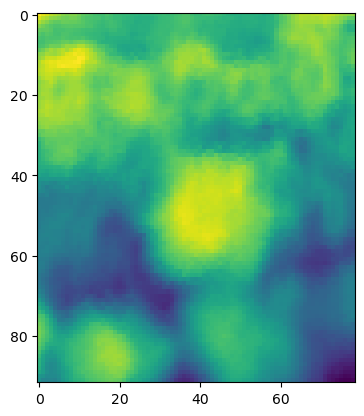

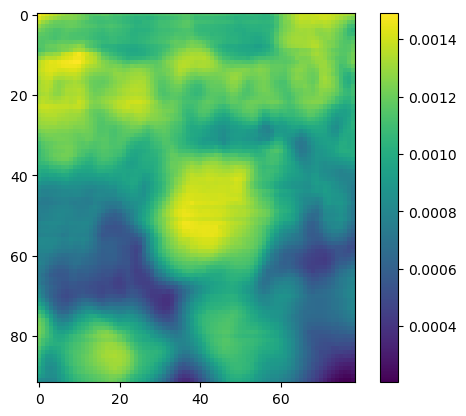

In [537]:
plt.imshow(tmp[19,:,:])
plt.show()
plt.imshow(tmp2[19,:,:])
plt.colorbar()
plt.show()

In [538]:
labels_full = results['full']['labels']
labels_subsampled = results['d020'][0.001]['labels']
adjusted_rand_score(labels_full, labels_subsampled)

In [539]:
adjusted_rand_score(labels_full, labels_subsampled)

0.3669373965220476

In [544]:
cmap = plt.cm.get_cmap('Set1', rank)    # 11 discrete colors
cmaplist = [cmap(i) for i in range(cmap.N)]
bounds = np.linspace(0, rank, rank+1)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)

/var/folders/ft/w6n5p71s4fbbpd1dypjt09sm0000gs/T/ipykernel_92517/2377904264.py:1: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('Set1', rank)    # 11 discrete colors


/var/folders/ft/w6n5p71s4fbbpd1dypjt09sm0000gs/T/ipykernel_4581/2154323716.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('Set1', rank)    # 11 discrete colors


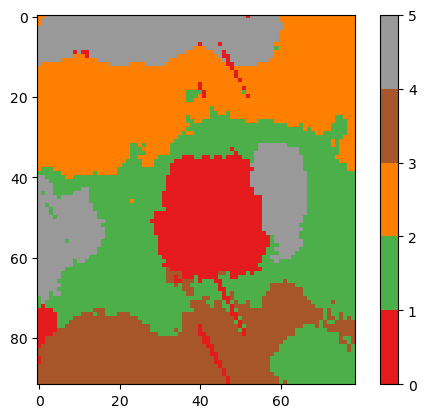

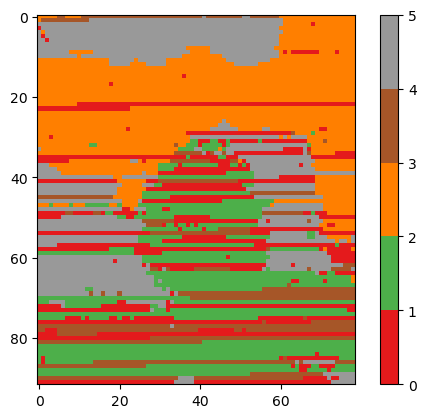

In [37]:
rank = results['full']['rank']

cmap = plt.cm.get_cmap('Set1', rank)    # 11 discrete colors
cmaplist = [cmap(i) for i in range(cmap.N)]
bounds = np.linspace(0, rank, rank+1)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)

shape = results['full']['tensor_shape'][1:]
plt.imshow(labels_full.reshape(shape),
            cmap=cmap, norm=norm)
plt.colorbar()
plt.show()

plt.imshow(labels_subsampled.reshape(shape),
            cmap=cmap, norm=norm)
plt.colorbar()
plt.show()

In [150]:
results['full']['labels']
x_full = results['full']['x'].reshape([40,40,152])

In [66]:
results['d035'][0.01]['error_lrps']

0.4196456919662649

In [67]:
x_l, x_s = results['d035'][0.01]['x_recon']
x = (x_l + x_s).reshape([40,40,152])

In [77]:
x = x_l + x_s

In [79]:
u, s, vh = np.linalg.svd(x_l.reshape([40**2, 152]),)

In [85]:
u = u[:,:7]

In [106]:
from sklearn.cluster import KMeans 
from sklearn.preprocessing import StandardScaler

In [108]:
scaler = StandardScaler()
scaler.fit(u)
u = scaler.transform(u)
kmeans = KMeans(n_clusters=7, random_state=0, n_init="auto").fit(u)

In [147]:
kmeans.labels_

array([1, 0, 0, ..., 0, 0, 0], dtype=int32)

In [144]:
cmap = plt.cm.get_cmap('Set1', 7)    # 11 discrete colors
cmaplist = [cmap(i) for i in range(cmap.N)]
bounds = np.linspace(0, 7, 8)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)

/var/folders/ft/w6n5p71s4fbbpd1dypjt09sm0000gs/T/ipykernel_92517/853725821.py:1: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('Set1', 7)    # 11 discrete colors


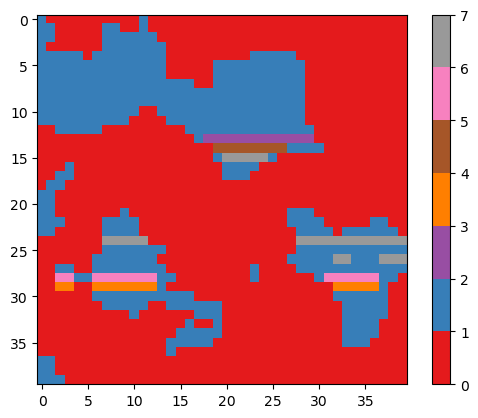

In [145]:
plt.imshow(kmeans.labels_.reshape([40,40]),
            cmap=cmap, norm=norm)
plt.colorbar()

In [ ]:
from sklearn.cluster import KMeans 
from sklearn.preprocessing import StandardScaler

s.cluster_analysis(
   cluster_source="signal", algorithm=KMeans(n_clusters=3, n_init=8)
   ) 

In [92]:
u[5,:]

array([-0.00447549, -0.00034277,  0.00105755,  0.00095104,  0.00045945,
        0.00110252, -0.00204512])

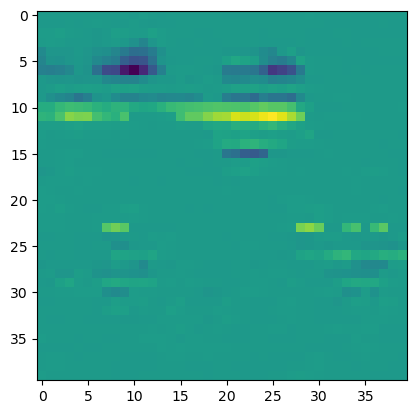

In [91]:
plt.imshow(u[:,4].reshape([40,40]))

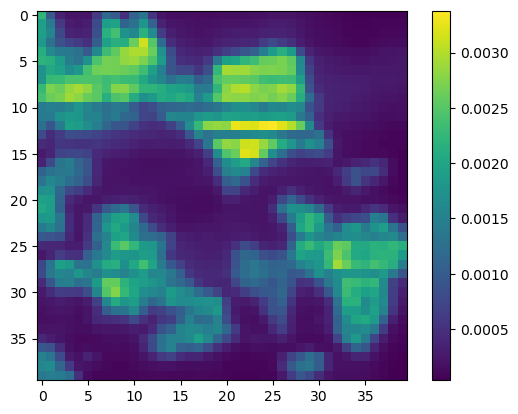

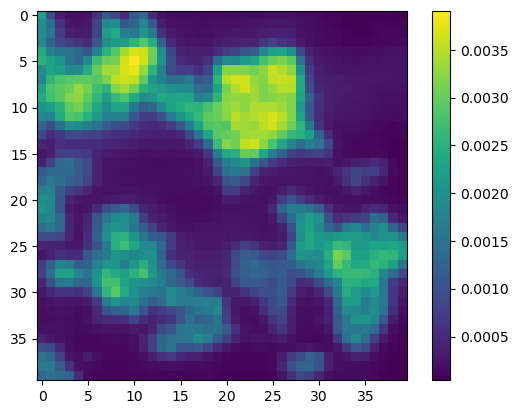

In [76]:
plt.imshow(x.mean(axis=2))
plt.colorbar()
plt.show()
plt.imshow(x_full.mean(axis=2))
plt.colorbar()
plt.show()

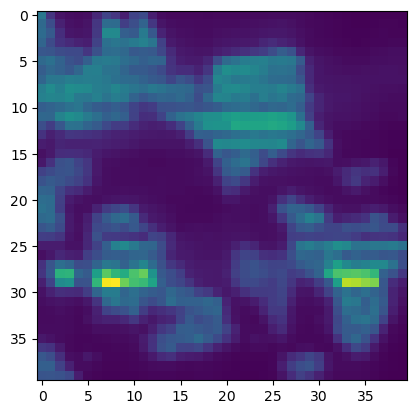

In [64]:
plt.imshow(x[:,:,4])

In [40]:
results['d015'][0.1]['error_lrps']

0.0052142620970719745

In [142]:
# Print all root level object names (aka keys) 
# # these can be group or dataset names 
# print("Keys: %s" % f.keys())
# # get first object name/key; may or may NOT be a group
# a_group_key = list(f.keys())[0]

# # get the object type for a_group_key: usually group or dataset
# print(type(f[a_group_key])) 

# # If a_group_key is a group name, 
# # this gets the object names in the group and returns as a list
# data = list(f[a_group_key])

# # If a_group_key is a dataset name, 
# # this gets the dataset values and returns as a list
# data = list(f[a_group_key])
# # preferred methods to get dataset values:
# ds_obj = f[a_group_key]      # returns as a h5py dataset object

In [144]:
def load_hdf5(filename):
    f = h5py.File(filename,'r+')
    return(f['exchange']['data'][()])

In [250]:
X = load_hdf5('../data/DS4.hdf5')
X_sub = load_hdf5('../data/DS4-035.hdf5')
mask = np.array(np.where(np.abs(X_sub.flatten() + 1) > 1e-10)).flatten()

In [299]:
mask = np.array(np.where(np.abs(X.flatten() + 1) > 1e-10)).flatten()

In [307]:
np.prod(np.shape(X))

243200

In [301]:
mask.shape

(243200,)

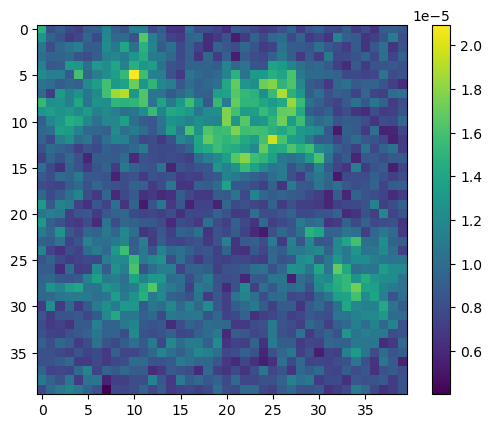

In [309]:
plt.imshow(X[:,:,4])
plt.colorbar()

In [255]:
u, s, vh = np.linalg.svd(X.reshape([np.prod(X.shape[:2]), X.shape[2]]))

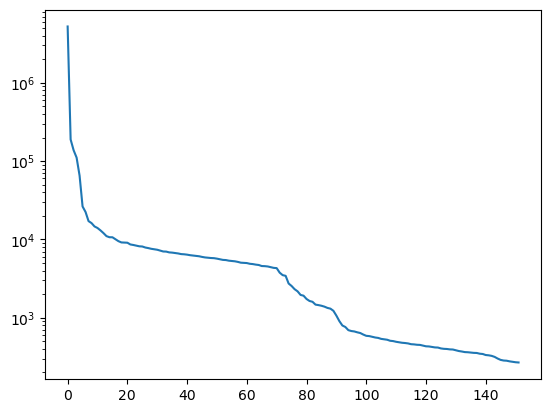

In [256]:
plt.semilogy(s)

In [257]:
X_norm = np.linalg.norm(X)
X = X / X_norm

In [258]:
data_mat = X.reshape([np.prod(X.shape[:2]), X.shape[2]])
m = data_mat.shape[0]
n = data_mat.shape[1]

In [296]:
rho_s = 0.1
delta = 0.33

p = round(delta*m*n)
s = round(rho_s*m*n)
r = 6
print(str(r) +','+ str(s))

HTr = FixedRank(r, (m,n))
HTs = Sparsity(s)

# Prepare transform and right-hand side
#mask = np.random.choice(m*n,p,replace = False)
P_omega = EntryWise(mask, m*n)
#P_omega = RasterScan(X.shape, round(delta*80))
b = P_omega.matvec(data_mat.flatten())

solver = NAHT(logverbosity = 2, maxiter = 500, verbosity = 2, minreldecrease = 1-1e-3, minreldecrease_shift = 50)
problem = LinearProblemSum(P_omega, b, (HTr, HTs))

6,24320


In [297]:
x, opt_log = solver.solve(problem)
x_l = x[0].reshape(m, n)
x_s = x[1].reshape(m, n)

np.linalg.norm(x_l +x_s - data_mat) / np.linalg.norm(data_mat)

 iter		   obj. value	    grad. norm
    1	+1.7122103198203092e-04	3.29508127e-01
    2	+1.0253994370726033e-04	1.51860928e-02
    3	+7.4722993460168399e-05	1.27951258e-02
    4	+6.0102632084702519e-05	1.13458624e-02
    5	+5.2186734490804045e-05	1.04055505e-02
    6	+4.6589366050954973e-05	9.82455588e-03
    7	+4.2836758838254767e-05	9.37372766e-03
    8	+3.9911593617816514e-05	9.03557278e-03
    9	+3.7587775132888144e-05	8.74714426e-03
   10	+3.5460086259894826e-05	8.51179668e-03
   11	+3.3792685976648997e-05	8.29135707e-03
   12	+3.2412679439633923e-05	8.11003625e-03
   13	+3.1202459995525669e-05	7.94877315e-03
   14	+3.0206750650428167e-05	7.81452134e-03
   15	+2.9425346875488552e-05	7.70396425e-03
   16	+2.8722825786651157e-05	7.61199313e-03
   17	+2.8088153908380848e-05	7.52259430e-03
   18	+2.7515448556537129e-05	7.44187983e-03
   19	+2.7009406004727063e-05	7.37038885e-03
   20	+2.6553505989633339e-05	7.30699101e-03
   21	+2.6131568498555171e-05	7.24751943e-03
   22	+2.5747593208

0.542796584211246

In [298]:
#0.1
np.linalg.norm(x_l +x_s - data_mat) / np.linalg.norm(data_mat)

0.542796584211246

In [295]:
#0.01
np.linalg.norm(x_l +x_s - data_mat) / np.linalg.norm(data_mat)

0.3865585042939414

In [292]:
#0.001
np.linalg.norm(x_l +x_s - data_mat) / np.linalg.norm(data_mat)

0.434518928755416

In [285]:
#0.00001
np.linalg.norm(x_l +x_s - data_mat) / np.linalg.norm(data_mat)

0.4583515953908142

In [286]:
#0.001
np.linalg.norm(x_l +x_s - data_mat) / np.linalg.norm(data_mat)

0.4583515953908142

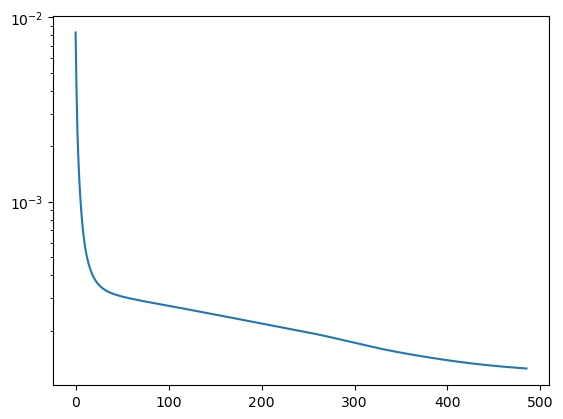

In [287]:
plt.semilogy(opt_log['iterations']['fx'])

In [288]:
x_l_tens = x_l.reshape(X.shape)
x_s_tens = x_s.reshape(X.shape)

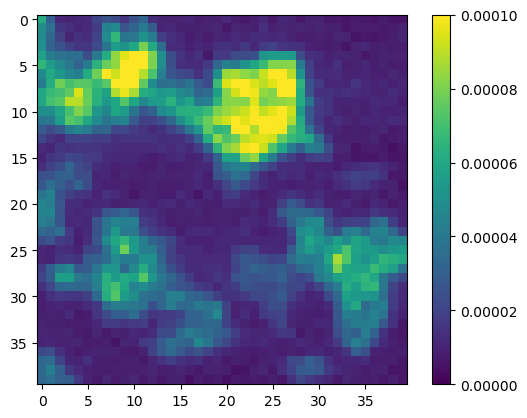

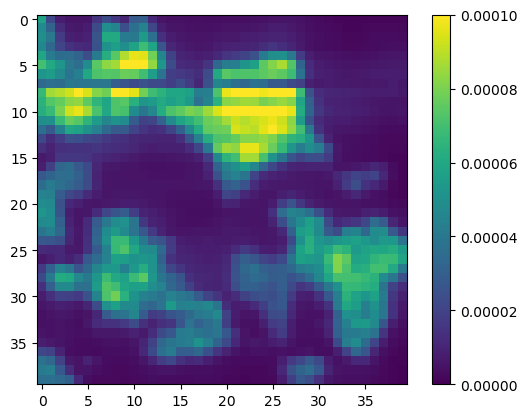

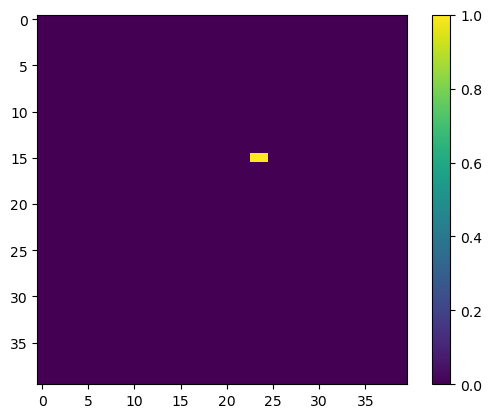

In [289]:
plt.imshow(X[:,:,40])
plt.colorbar()
plt.clim([0, 1e-4])
plt.show()
plt.imshow((x_l_tens+x_s_tens)[:,:,40])
plt.clim([0, 1e-4])
plt.colorbar()
plt.show()
plt.imshow(x_s_tens[:,:,:].any(axis=2))
plt.colorbar()
plt.show()


In [134]:
mask = RasterScan((5,5,3), 0.3)

In [142]:
mask[:,:,2]

array([[1., 1., 1., 1., 1.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [1., 1., 1., 1., 1.],
       [0., 0., 0., 0., 0.]])